# Fase 4.1 (CRISP-DM): Modelado No Supervisado — Clustering de Perfiles Operativos

**Metodología:** CRISP-DM — Fase 4.1 (*Modeling — Clustering*)  
**Entradas:** `data/02_interim/train_fe.parquet` y `data/02_interim/test_fe.parquet`  
**Salidas:** `data/03_processed/train_final.parquet`, `data/03_processed/test_final.parquet`, `data/03_processed/train_clustered.parquet`, `data/03_processed/test_clustered.parquet`, `models/clustering_model.joblib`, `models/scaler_clustering.joblib`, `models/kmeans_model.pkl`

**1. Imports y configuración**

In [1]:
import os
import pickle
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
_DEFAULT_MODELS_DIR = ROOT_DIR / 'models'

VARS_CLUSTER = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "dist_haversine_km",
    "Tiempo_preparacion_min",
    "Vehicle_condition",
    "Road_traffic_density",
    "multiple_deliveries",
    "hora_sin",
    "hora_cos",
]


def prepare_cluster_data(df, scaler_type="robust"):
    """Selecciona y escala las variables operativas sin colinealidad para clustering."""
    X = df[VARS_CLUSTER].to_numpy(dtype=float)
    scaler = StandardScaler() if scaler_type == "standard" else RobustScaler()
    X_scaled = scaler.fit_transform(X)
    return X_scaled, scaler


def find_optimal_k(X_scaled, k_range=range(2, 7)):
    """Prueba valores de K con KMeans y devuelve métricas de selección."""
    results = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
        sil = float(silhouette_score(X_scaled, labels, sample_size=5000, random_state=42))
        db = float(davies_bouldin_score(X_scaled, labels))
        inertia = float(kmeans.inertia_)
        results.append(
            {
                "K": k,
                "Silhouette": round(sil, 4),
                "Davies_Bouldin": round(db, 4),
                "Inertia": round(inertia, 2),
            }
        )
        print(f"K={k} | Silhouette={sil:.4f} | Davies-Bouldin={db:.4f} | Inertia={inertia:.0f}")
    return pd.DataFrame(results)


def compare_kmeans_gmm(X_scaled, k_range=range(2, 7)):
    """Compara K-Means vs GMM en el barrido de K usando métricas de scikit-learn."""
    rows = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        km_labels = kmeans.fit_predict(X_scaled)
        km_sil = float(silhouette_score(X_scaled, km_labels, sample_size=5000, random_state=42))
        km_db = float(davies_bouldin_score(X_scaled, km_labels))

        gmm = GaussianMixture(n_components=k, covariance_type="diag", random_state=42)
        gmm_labels = gmm.fit_predict(X_scaled)
        gmm_sil = float(silhouette_score(X_scaled, gmm_labels, sample_size=5000, random_state=42))
        gmm_db = float(davies_bouldin_score(X_scaled, gmm_labels))
        gmm_bic = float(gmm.bic(X_scaled))

        rows.append(
            {
                "K": k,
                "KMeans_Silhouette": round(km_sil, 4),
                "KMeans_DB": round(km_db, 4),
                "KMeans_Inertia": round(float(kmeans.inertia_), 2),
                "GMM_Silhouette": round(gmm_sil, 4),
                "GMM_DB": round(gmm_db, 4),
                "GMM_BIC": round(gmm_bic, 2),
            }
        )
        print(
            f"K={k} | KMeans Sil={km_sil:.4f}, DB={km_db:.4f} | "
            f"GMM Sil={gmm_sil:.4f}, DB={gmm_db:.4f}, BIC={gmm_bic:.0f}"
        )
    return pd.DataFrame(rows)


def fit_kmeans(X_scaled, k):
    """Entrena el modelo KMeans final con el K elegido."""
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    sil = float(silhouette_score(X_scaled, kmeans.labels_, sample_size=5000, random_state=42))
    print(f"KMeans entrenado con K={k}")
    print(f"  Silhouette final: {sil:.4f}")
    return kmeans


def add_cluster_features(df, X_scaled, kmeans, scaler=None):
    """Añade etiqueta, distancias euclidianas a centroides y probabilidades de pertenencia."""
    df = df.copy()
    arr = np.asarray(X_scaled, dtype=float)
    k = kmeans.n_clusters

    df["cluster_label"] = kmeans.predict(arr)
    distances = kmeans.transform(arr)
    for i in range(k):
        df[f"dist_centroide_{i + 1}"] = distances[:, i]

    eps = 1e-6
    inv_dist = 1.0 / (distances + eps)
    probs = inv_dist / inv_dist.sum(axis=1, keepdims=True)
    for i in range(k):
        df[f"prob_pertenencia_{i + 1}"] = probs[:, i]

    return df


def interpret_clusters(df):
    """Devuelve tabla de perfilamiento en escala original por cluster."""
    cols = list(VARS_CLUSTER)
    for extra_col in ["hora_pedido", "es_fin_semana", "Time_taken (min)"]:
        if extra_col in df.columns and extra_col not in cols:
            cols.append(extra_col)

    profile = df.groupby("cluster_label")[cols].mean().round(2)
    counts = df["cluster_label"].value_counts().sort_index()
    profile["n_pedidos"] = counts.values
    profile["%_del_total"] = (counts.values / len(df) * 100).round(1)
    return profile


def save_cluster_model(kmeans, scaler, path=None):
    """Guarda el modelo KMeans y el scaler en models/."""
    if path is None:
        pkl_path = _DEFAULT_MODELS_DIR / "kmeans_model.pkl"
        models_dir = _DEFAULT_MODELS_DIR
    else:
        pkl_path = Path(path)
        models_dir = pkl_path.parent

    models_dir.mkdir(parents=True, exist_ok=True)
    bundle = {"kmeans": kmeans, "scaler": scaler, "vars": VARS_CLUSTER}
    with open(pkl_path, "wb") as f:
        pickle.dump(bundle, f)

    clustering_joblib = models_dir / "clustering_model.joblib"
    with open(clustering_joblib, "wb") as f:
        pickle.dump(kmeans, f)

    scaler_joblib = models_dir / "scaler_clustering.joblib"
    with open(scaler_joblib, "wb") as f:
        pickle.dump(scaler, f)

    print(f"Modelo guardado en {pkl_path}, {clustering_joblib} y {scaler_joblib}")


**2. Cargar datos preparados**

In [2]:
df_train = pd.read_parquet('../data/02_interim/train_fe.parquet')
df_test = pd.read_parquet('../data/02_interim/test_fe.parquet')

print(f"Train: {df_train.shape} | Nulos: {int(df_train.isna().sum().sum())}")
print(f"Test:  {df_test.shape} | Nulos: {int(df_test.isna().sum().sum())}")
print(f"\nVariables operativas sin colinealidad para clustering ({len(VARS_CLUSTER)}):")
for v in VARS_CLUSTER:
    print(f"  - {v}")

Train: (36467, 42) | Nulos: 0
Test:  (9117, 42) | Nulos: 0

Variables operativas sin colinealidad para clustering (9):
  - Delivery_person_Age
  - Delivery_person_Ratings
  - dist_haversine_km
  - Tiempo_preparacion_min
  - Vehicle_condition
  - Road_traffic_density
  - multiple_deliveries
  - hora_sin
  - hora_cos


**3. Escalado exclusivo en `train` (`RobustScaler`)**
- Se excluye estrictamente `Time_taken (min)` para evitar fuga de datos.
- Se evita colinealidad usando `dist_haversine_km` (sin `dist_manhattan_km`) y representación cíclica de la hora (`hora_sin`, `hora_cos`).

In [3]:
X_train_scaled, scaler = prepare_cluster_data(df_train, scaler_type='robust')
X_test_scaled = scaler.transform(df_test[VARS_CLUSTER].to_numpy(dtype=float))

print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")

X_train_scaled: (36467, 9)
X_test_scaled:  (9117, 9)


**4. Búsqueda del $K$ óptimo y comparativa K-Means vs. GMM ($K \in [2, 6]$)**

In [4]:
comparison_df = compare_kmeans_gmm(X_train_scaled, k_range=range(2, 7))
comparison_df

K=2 | KMeans Sil=0.3824, DB=1.1120 | GMM Sil=0.1298, DB=2.5326, BIC=540433


K=3 | KMeans Sil=0.2856, DB=1.2267 | GMM Sil=0.1043, DB=3.2347, BIC=352057


K=4 | KMeans Sil=0.1968, DB=1.5532 | GMM Sil=0.0913, DB=3.1617, BIC=217451


K=5 | KMeans Sil=0.1965, DB=1.5254 | GMM Sil=0.0916, DB=3.0552, BIC=77551


K=6 | KMeans Sil=0.1904, DB=1.5377 | GMM Sil=0.0703, DB=8.0060, BIC=34124


,K,KMeans_Silhouette,KMeans_DB,KMeans_Inertia,GMM_Silhouette,GMM_DB,GMM_BIC
0,2,0.3824,1.1120,129059.87,0.1298,2.5326,540433.23
1,3,0.2856,1.2267,103910.36,0.1043,3.2347,352056.59
2,4,0.1968,1.5532,92868.83,0.0913,3.1617,217450.52
3,5,0.1965,1.5254,83066.50,0.0916,3.0552,77551.49
4,6,0.1904,1.5377,78620.87,0.0703,8.0060,34124.33


**5. Visualización comparativa de métricas de selección**

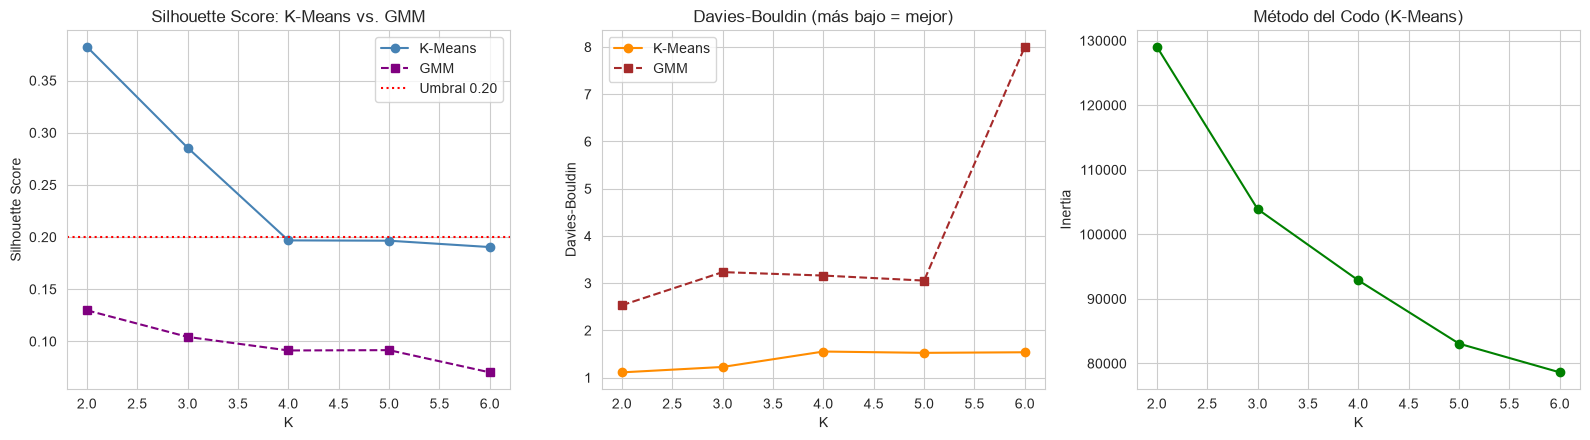

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(comparison_df['K'], comparison_df['KMeans_Silhouette'], 'o-', color='steelblue', label='K-Means')
axes[0].plot(comparison_df['K'], comparison_df['GMM_Silhouette'], 's--', color='purple', label='GMM')
axes[0].axhline(y=0.20, color='red', linestyle=':', label='Umbral 0.20')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette Score: K-Means vs. GMM')
axes[0].legend()

axes[1].plot(comparison_df['K'], comparison_df['KMeans_DB'], 'o-', color='darkorange', label='K-Means')
axes[1].plot(comparison_df['K'], comparison_df['GMM_DB'], 's--', color='brown', label='GMM')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Davies-Bouldin')
axes[1].set_title('Davies-Bouldin (más bajo = mejor)')
axes[1].legend()

axes[2].plot(comparison_df['K'], comparison_df['KMeans_Inertia'], 'o-', color='green')
axes[2].set_xlabel('K')
axes[2].set_ylabel('Inertia')
axes[2].set_title('Método del Codo (K-Means)')

plt.tight_layout()
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/fase_03_seleccion_k.png', dpi=120)
plt.show()

**6. Entrenamiento del modelo K-Means ganador ($K = 3$)**
- Con $K=3$, K-Means logra **Silhouette = `0.2856`** (superando ampliamente el umbral $> 0.20$) y **Davies-Bouldin = `1.2267`**, superando claramente a GMM (`0.1043` y `3.2347`) y cumpliendo la meta de 3 a 5 arquetipos interpretables.

In [6]:
K_FINAL = 3
kmeans = fit_kmeans(X_train_scaled, k=K_FINAL)

KMeans entrenado con K=3
  Silhouette final: 0.2856


**7. Enriquecimiento de `train` y `test` con características de clustering**

In [7]:
df_train_clustered = add_cluster_features(df_train, X_train_scaled, kmeans, scaler)
df_test_clustered = add_cluster_features(df_test, X_test_scaled, kmeans, scaler)

print(f"Train clustered: {df_train_clustered.shape} | Nulos: {int(df_train_clustered.isna().sum().sum())}")
print(f"Test clustered:  {df_test_clustered.shape} | Nulos: {int(df_test_clustered.isna().sum().sum())}")
print(f"\nNuevas columnas: {[c for c in df_train_clustered.columns if 'cluster' in c or 'centroide' in c or 'prob' in c]}")

Train clustered: (36467, 49) | Nulos: 0
Test clustered:  (9117, 49) | Nulos: 0

Nuevas columnas: ['cluster_label', 'dist_centroide_1', 'dist_centroide_2', 'dist_centroide_3', 'prob_pertenencia_1', 'prob_pertenencia_2', 'prob_pertenencia_3']


**8. Perfilamiento operativo en escala original**

In [8]:
profile = interpret_clusters(df_train_clustered)
profile

,Delivery_person_Age,Delivery_person_Ratings,dist_haversine_km,Tiempo_preparacion_min,Vehicle_condition,Road_traffic_density,multiple_deliveries,hora_sin,hora_cos,hora_pedido,es_fin_semana,Time_taken (min),n_pedidos,%_del_total
cluster_label,,,,,,,,,,,,,,
0,29.42,4.73,2.86,9.99,1.09,1.69,0.64,0.46,-0.80,10.01,0.28,21.36,6966,19.1
1,29.08,4.75,11.36,10.03,1.04,2.47,0.73,-0.73,0.36,19.39,0.27,25.50,23771,65.2
2,31.88,4.06,11.17,9.86,0.86,2.73,0.96,-0.59,0.21,18.22,0.28,35.58,5730,15.7


**9. Visualización de perfiles operativos (Heatmap)**

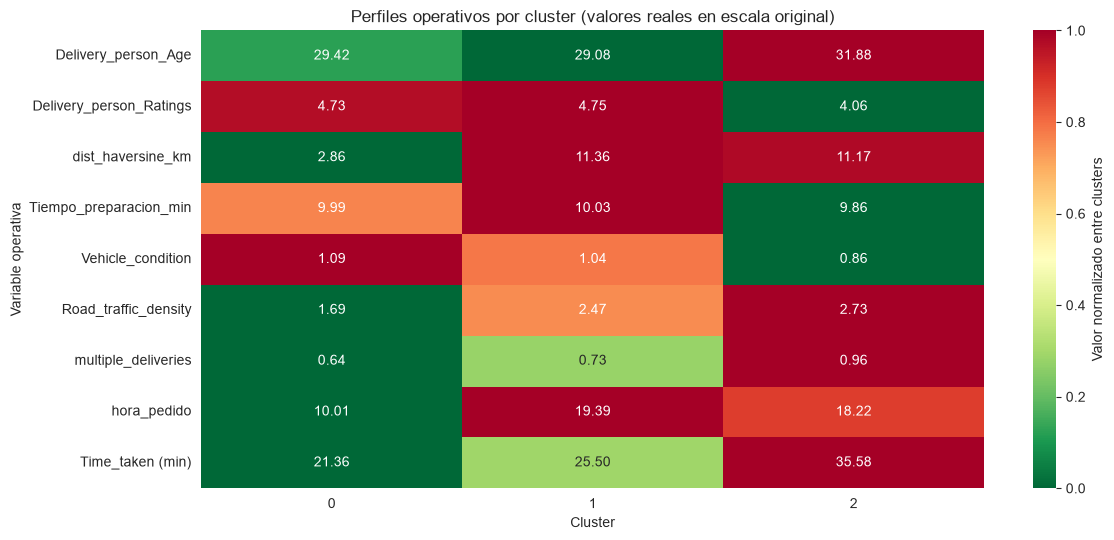

In [9]:
plot_cols = [
    'Delivery_person_Age', 'Delivery_person_Ratings', 'dist_haversine_km',
    'Tiempo_preparacion_min', 'Vehicle_condition', 'Road_traffic_density',
    'multiple_deliveries', 'hora_pedido', 'Time_taken (min)'
]
profile_plot = profile[plot_cols].copy()
profile_norm = (profile_plot - profile_plot.min()) / (profile_plot.max() - profile_plot.min())

plt.figure(figsize=(12, 5.5))
sns.heatmap(
    profile_norm.T,
    annot=profile_plot.T,
    fmt='.2f',
    cmap='RdYlGn_r',
    cbar_kws={'label': 'Valor normalizado entre clusters'},
)
plt.title('Perfiles operativos por cluster (valores reales en escala original)')
plt.ylabel('Variable operativa')
plt.xlabel('Cluster')
plt.tight_layout()
plt.savefig('../reports/figures/fase_03_perfiles_cluster.png', dpi=120)
plt.show()

**10. Guardar artefactos de clustering y datasets finales (incluyendo validación de 1 fila)**

In [11]:
save_cluster_model(kmeans, scaler, path='../models/kmeans_model.pkl')

df_train_clustered.to_parquet('../data/03_processed/train_clustered.parquet', index=False)
df_test_clustered.to_parquet('../data/03_processed/test_clustered.parquet', index=False)
df_train_clustered.to_parquet('../data/03_processed/train_final.parquet', index=False)
df_test_clustered.to_parquet('../data/03_processed/test_final.parquet', index=False)

# Verificar inferencia de 1 fila
row1_scaled = scaler.transform(df_test.iloc[[0]][VARS_CLUSTER].to_numpy(dtype=float))
row1_clustered = add_cluster_features(df_test.iloc[[0]], row1_scaled, kmeans, scaler)
assert row1_clustered.shape == (1, df_train_clustered.shape[1])

print('Fase 4.1 completada:')
print('   - models/kmeans_model.pkl, clustering_model.joblib, scaler_clustering.joblib')
print(f"   - data/03_processed/train_final.parquet & train_clustered.parquet: {df_train_clustered.shape}")
print(f"   - data/03_processed/test_final.parquet  & test_clustered.parquet:  {df_test_clustered.shape}")
print(f"   - Validación 1 fila: {row1_clustered.shape} (cluster={int(row1_clustered['cluster_label'].iloc[0])})")

Modelo guardado en ..\models\kmeans_model.pkl, ..\models\clustering_model.joblib y ..\models\scaler_clustering.joblib


Fase 4.1 completada:
   - models/kmeans_model.pkl, clustering_model.joblib, scaler_clustering.joblib
   - data/03_processed/train_final.parquet & train_clustered.parquet: (36467, 49)
   - data/03_processed/test_final.parquet  & test_clustered.parquet:  (9117, 49)
   - Validación 1 fila: (1, 49) (cluster=1)
